In [19]:
# %%
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from sklearn.metrics import mean_squared_error, mean_absolute_error

%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.grid'] = True


In [20]:
from pathlib import Path
import os

# Current working dir should be: graphCeylon-API/models/recommender_service
NOTEBOOK_DIR = Path.cwd()

# Repo root = parent of 'models'
REPO_ROOT = NOTEBOOK_DIR.parents[1]   # -> /Users/dev/Desktop/graphCeylon-API

# Folder where cleaned_history.csv actually is
DATA_DIR = REPO_ROOT / "data" / "recommender_service" / "raw" / "data_raw" / "weather"
csv_path = DATA_DIR / "cleaned_history.csv"

print("Reading from:", csv_path)
df = pd.read_csv(csv_path, parse_dates=["date"])
print(df.head())


Reading from: /Users/dev/Desktop/graphCeylon-API/data/recommender_service/raw/data_raw/weather/cleaned_history.csv
        date  location_id  avg_temp  rainfall
0 2021-01-01  adam's_peak     15.55      91.4
1 2021-02-01  adam's_peak     15.40      59.2
2 2021-03-01  adam's_peak     16.15     108.7
3 2021-04-01  adam's_peak     16.60     107.2
4 2021-05-01  adam's_peak     17.20     273.2


In [21]:
def cap_rain_outliers_by_month(ts, high_q=0.98):
    """
    For each calendar month (Jan, Feb, ...), cap rainfall above the
    high_q quantile (e.g. 98th percentile). This keeps realistic
    heavy-rain events but trims freak extremes.
    """
    ts = ts.copy()
    month = ts.index.month
    capped = ts.copy()
    total_hi = 0

    for m in range(1, 13):
        mask = (month == m)
        if mask.sum() == 0:
            continue

        sub = ts[mask]
        upper = sub.quantile(high_q)

        hi_mask = sub > upper
        total_hi += hi_mask.sum()

        capped.loc[mask] = sub.clip(upper=upper)

    print(f"Rain: capped {total_hi} high outliers above {high_q*100:.1f}th percentile")
    return capped


In [22]:
# %%
def cap_temp_outliers_by_month(ts, z_thresh=3.0, hard_clip=(5, 32)):
    """
    Cap temp outliers per calendar month (so Jan is compared with other Jans).
    Optionally hard-clip to physical limits.
    """
    ts = ts.copy()
    month = ts.index.month
    capped = ts.copy()
    total_hi = total_lo = 0

    for m in range(1, 13):
        mask = (month == m)
        if mask.sum() == 0:
            continue

        sub = ts[mask]
        mean = sub.mean()
        std = sub.std()
        upper = mean + z_thresh * std
        lower = mean - z_thresh * std

        hi_mask = (sub > upper)
        lo_mask = (sub < lower)
        total_hi += hi_mask.sum()
        total_lo += lo_mask.sum()

        capped.loc[mask] = sub.clip(lower=lower, upper=upper)

    if hard_clip is not None:
        capped = capped.clip(lower=hard_clip[0], upper=hard_clip[1])

    print(f"Month-wise capping: {total_hi} high and {total_lo} low outliers (z>{z_thresh})")
    return capped


def smooth_spikes(series, max_diff=2.5):
    """
    Extra protection: if any point jumps more than max_diff °C from the
    previous month, clip it to previous + max_diff (or -max_diff).
    This will kill the final 28°C spike you saw.
    """
    s = series.copy()
    for i in range(1, len(s)):
        diff = s.iloc[i] - s.iloc[i - 1]
        if abs(diff) > max_diff:
            s.iloc[i] = s.iloc[i - 1] + np.sign(diff) * max_diff
    return s


In [23]:
def make_rain_series(df, location_id, rain_col="rainfall"):
    """
    Returns:
        ts_log_rain: log-transformed monthly rainfall (cleaned)
        ts_rain_mm:  monthly rainfall in mm (cleaned)
    """

    # Filter for location
    rain_loc_df = (
        df[df["location_id"] == location_id]
        .sort_values("date")
        .copy()
    )

    if rain_loc_df.empty:
        raise ValueError(f"No rainfall data found for location_id={location_id!r}")

    # Enforce monthly frequency
    rain_loc_df = rain_loc_df.set_index("date").asfreq("MS")

    # Step 1: interpolate missing values
    rain_mm_raw = rain_loc_df[rain_col].interpolate(limit_direction="both")

    # Step 2: cap extreme outliers by month
    rain_mm_capped = cap_rain_outliers_by_month(rain_mm_raw, high_q=0.98)

    # Step 3: log transform (SARIMA works better)
    ts_log_rain = np.log1p(rain_mm_capped)

    # Return both log series and mm series
    return ts_log_rain, rain_mm_capped


Month-wise capping: 0 high and 0 low outliers (z>3.0)


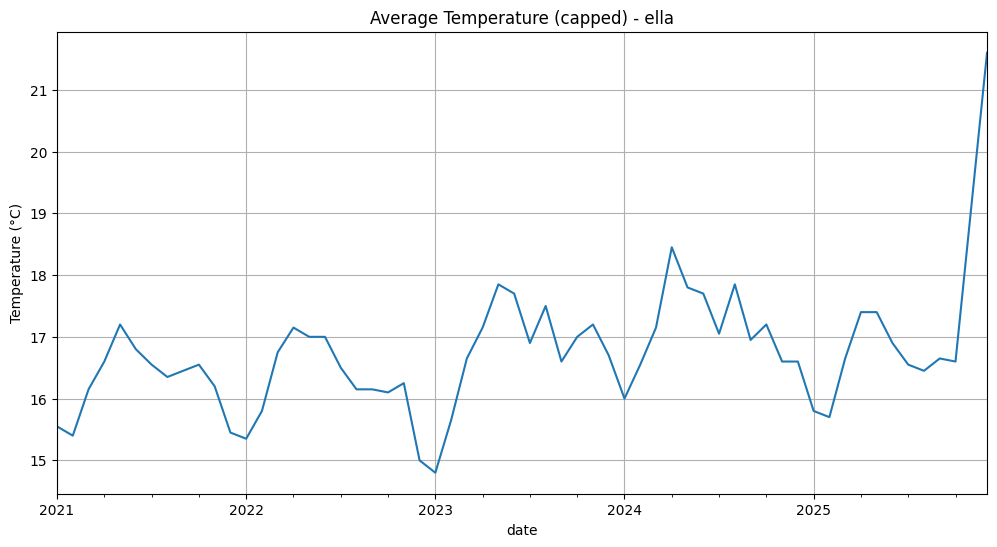

ella: 60 monthly observations.


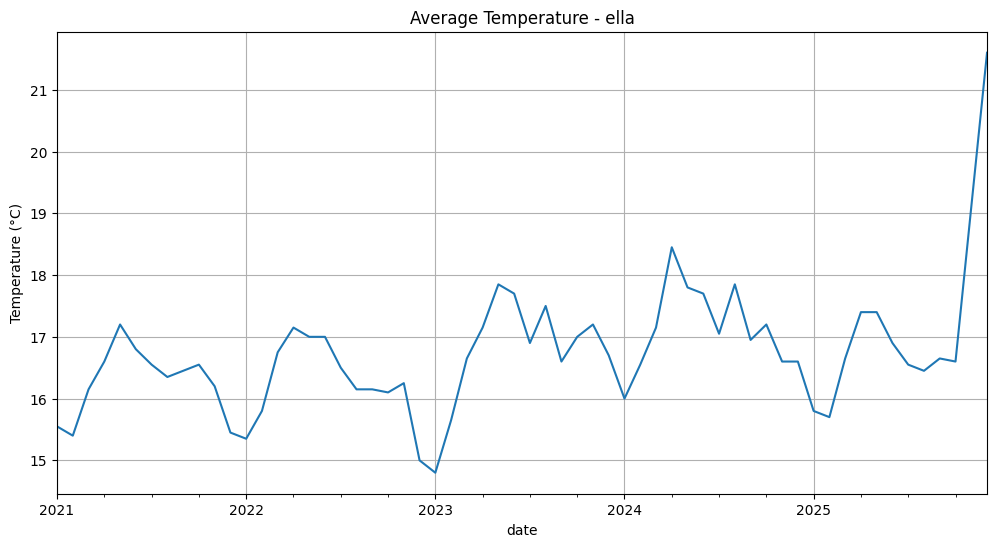

Rain: capped 12 high outliers above 98.0th percentile
ella: 60 monthly rainfall observations.


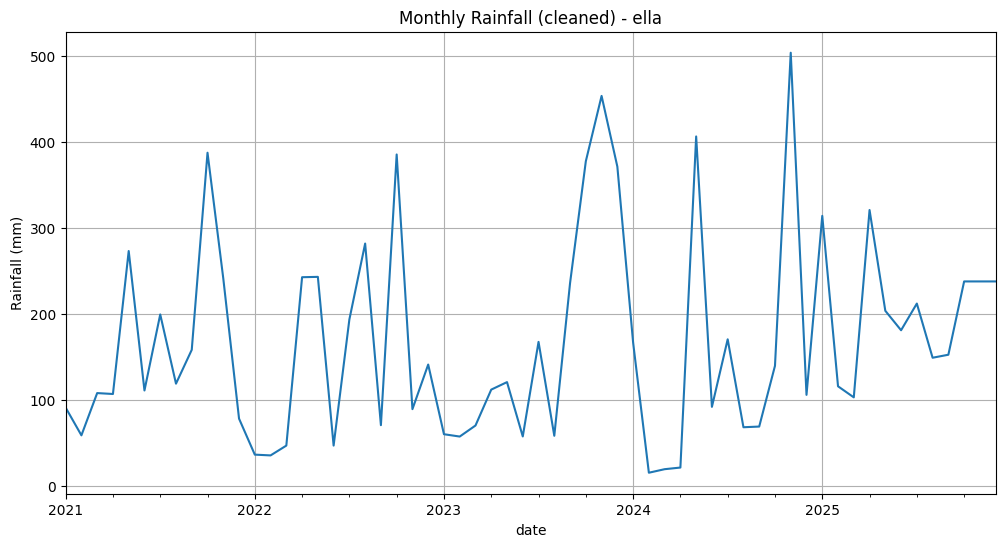

In [24]:
# %%
# === Single-location SARIMA development ===
# Pick one location_id to develop & debug the model.

location_id = 'ella'  # <-- change this to test other locations

loc_df = (
    df[df['location_id'] == location_id]
    .sort_values('date')
    .copy()
)

if loc_df.empty:
    raise ValueError(f'No data found for location_id={location_id!r}')

# Set index and enforce monthly frequency
loc_df = loc_df.set_index('date').asfreq('MS')  # Month Start frequency


# Interpolate missing temperature values
ts_raw = loc_df['avg_temp'].interpolate(limit_direction='both')

# 1) Month-wise capping
ts_capped = cap_temp_outliers_by_month(ts_raw, z_thresh=3.0)

# 2) Local spike smoothing (handles that last 28°C)
ts = smooth_spikes(ts_capped, max_diff=2.5)



# Plot cleaned series
ts.plot(title=f'Average Temperature (capped) - {location_id}')
plt.ylabel('Temperature (°C)')
plt.show()

print(f'{location_id}: {len(ts)} monthly observations.')

ts.plot(title=f'Average Temperature - {location_id}')
plt.ylabel('Temperature (°C)')
plt.show()


# %%
# ==== RAINFALL SARIMA FOR SAME LOCATION ====================================

rain_location_id = location_id   # use same place as temperature, e.g. 'ella'

ts_log_rain, ts_rain_mm = make_rain_series(df, rain_location_id)

print(f'{rain_location_id}: {len(ts_rain_mm)} monthly rainfall observations.')

ts_rain_mm.plot(title=f'Monthly Rainfall (cleaned) - {rain_location_id}')
plt.ylabel('Rainfall (mm)')
plt.show()


Rain: capped 12 high outliers above 98.0th percentile


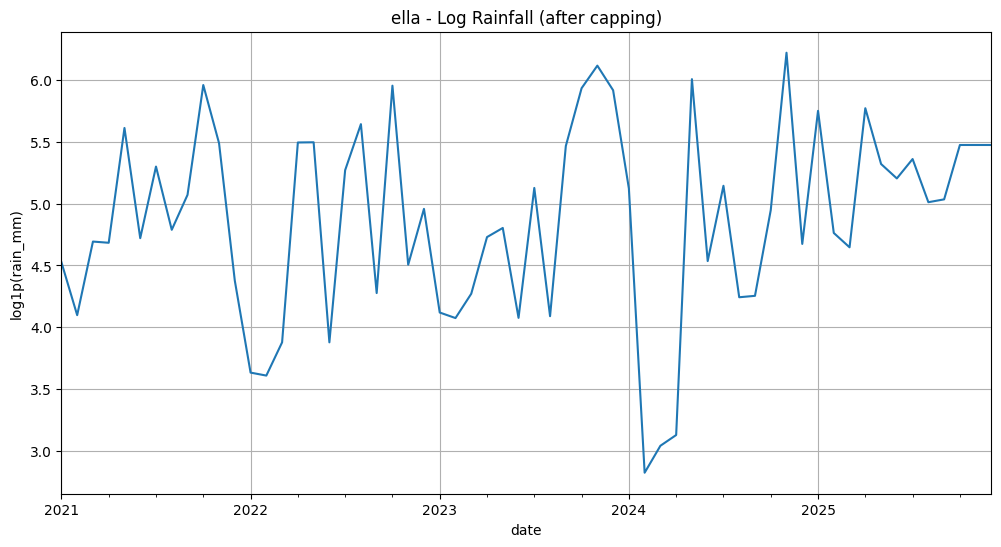

In [25]:
# %%
# === RAINFALL SERIES (ella) ===

# IMPORTANT: set this to the real rainfall column name in cleaned_history.csv
# e.g. "rainfall", "total_rain_mm", etc.
rain_col = "rainfall"   # <-- CHANGE IF NEEDED

rain_loc_df = (
    df[df["location_id"] == location_id]
    .sort_values("date")
    .copy()
)

if rain_loc_df.empty:
    raise ValueError(f"No data found for location_id={location_id!r} (rain)")

# enforce monthly frequency
rain_loc_df = rain_loc_df.set_index("date").asfreq("MS")

# 1) interpolate missing rain values
rain_mm_raw = rain_loc_df[rain_col].interpolate(limit_direction="both")

# 2) cap crazy extremes per calendar month (before log)
rain_mm_capped = cap_rain_outliers_by_month(rain_mm_raw, high_q=0.98)

# 3) log-transform (stabilises variance; handles skew)
ts_log_rain = np.log1p(rain_mm_capped)

# quick look on log scale
ts_log_rain.plot(title=f"{location_id} - Log Rainfall (after capping)")
plt.ylabel("log1p(rain_mm)")
plt.show()


Train range: 2021-01-01 → 2024-12-01
Test  range: 2025-01-01 → 2025-12-01


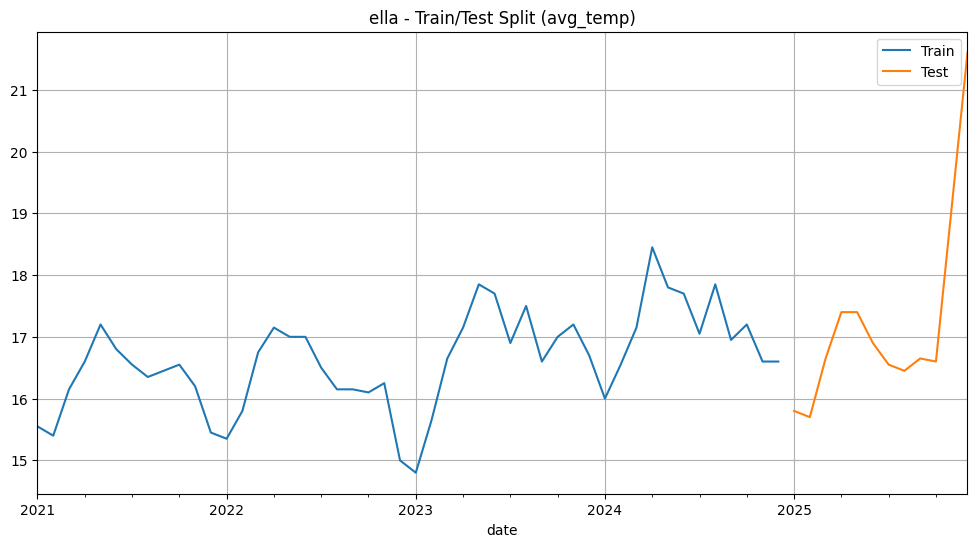

In [26]:
# %%
# Train/Test split (last 12 months as test)

test_horizon = 12  # months
if len(ts) <= test_horizon + 12:
    raise ValueError('Not enough data for a 12-month test split. Reduce test_horizon or add more history.')

train = ts.iloc[:-test_horizon]
test = ts.iloc[-test_horizon:]

print('Train range:', train.index[0].date(), '→', train.index[-1].date())
print('Test  range:', test.index[0].date(), '→', test.index[-1].date())

train.plot(label='Train')
test.plot(label='Test')
plt.legend()
plt.title(f'{location_id} - Train/Test Split (avg_temp)')
plt.show()


Rainfall train range: 2021-01-01 → 2024-12-01
Rainfall test  range: 2025-01-01 → 2025-12-01


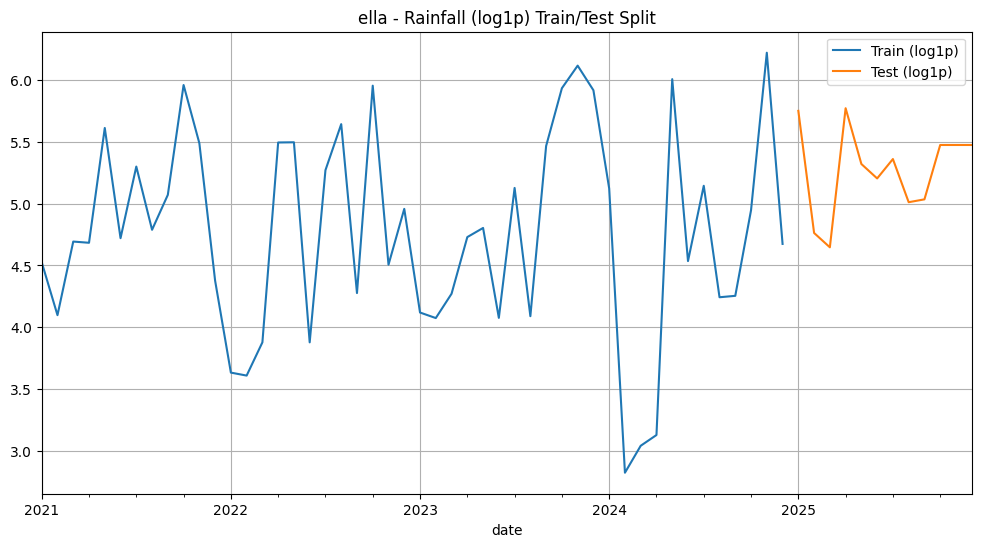

In [27]:
# %%
# Train/Test split for rainfall (last 12 months as test)
rain_test_horizon = 12

if len(ts_log_rain) <= rain_test_horizon + 12:
    raise ValueError('Not enough rainfall data for a 12-month test split.')

rain_train_log = ts_log_rain.iloc[:-rain_test_horizon]
rain_test_log  = ts_log_rain.iloc[-rain_test_horizon:]

print('Rainfall train range:', rain_train_log.index[0].date(), '→', rain_train_log.index[-1].date())
print('Rainfall test  range:', rain_test_log.index[0].date(),  '→', rain_test_log.index[-1].date())

rain_train_log.plot(label='Train (log1p)')
rain_test_log.plot(label='Test (log1p)')
plt.legend()
plt.title(f'{rain_location_id} - Rainfall (log1p) Train/Test Split')
plt.show()


In [28]:
# %%
# Install pmdarima if needed (uncomment if running the first time)
try:
    import pmdarima  # noqa: F401
    print('pmdarima already installed.')
except ImportError:
    %pip install -q pmdarima
    import pmdarima
    print('pmdarima installed.')

from pmdarima import auto_arima


pmdarima already installed.


In [29]:
# %%
# Use auto_arima to select best SARIMA order based on AIC
sarima_model = auto_arima(
    train,
    start_p=0, start_q=0,
    max_p=3, max_q=3,
    d=None,                # let auto_arima determine differencing via tests
    seasonal=True,
    m=12,                  # yearly seasonality for monthly data
    start_P=0, start_Q=0,
    max_P=2, max_Q=2,
    D=None,
    information_criterion='bic',
    trace=True,
    error_action='ignore',
    stepwise=True,
    suppress_warnings=True,
    n_jobs=-1,
)

print('\nBest SARIMA model found:')
print(sarima_model.summary())


Performing stepwise search to minimize bic
 ARIMA(0,0,0)(0,1,0)[12] intercept   : BIC=68.364, Time=0.01 sec
 ARIMA(1,0,0)(1,1,0)[12] intercept   : BIC=56.858, Time=0.03 sec
 ARIMA(0,0,1)(0,1,1)[12] intercept   : BIC=59.456, Time=0.04 sec
 ARIMA(0,0,0)(0,1,0)[12]             : BIC=73.472, Time=0.00 sec
 ARIMA(1,0,0)(0,1,0)[12] intercept   : BIC=56.611, Time=0.01 sec
 ARIMA(1,0,0)(0,1,1)[12] intercept   : BIC=56.521, Time=0.03 sec


/Users/dev/Desktop/graphCeylon-API/.venv_recommender/lib/python3.12/site-packages/pmdarima/arima/_validation.py:76: UserWarning: stepwise model cannot be fit in parallel (n_jobs=1). Falling back to stepwise parameter search.
  warnings.warn('stepwise model cannot be fit in parallel (n_jobs=%i). '


 ARIMA(1,0,0)(1,1,1)[12] intercept   : BIC=60.081, Time=0.07 sec
 ARIMA(1,0,0)(0,1,2)[12] intercept   : BIC=60.082, Time=0.08 sec
 ARIMA(1,0,0)(1,1,2)[12] intercept   : BIC=63.662, Time=0.29 sec
 ARIMA(0,0,0)(0,1,1)[12] intercept   : BIC=inf, Time=0.05 sec
 ARIMA(2,0,0)(0,1,1)[12] intercept   : BIC=56.491, Time=0.03 sec
 ARIMA(2,0,0)(0,1,0)[12] intercept   : BIC=57.497, Time=0.01 sec
 ARIMA(2,0,0)(1,1,1)[12] intercept   : BIC=60.049, Time=0.10 sec
 ARIMA(2,0,0)(0,1,2)[12] intercept   : BIC=60.039, Time=0.11 sec
 ARIMA(2,0,0)(1,1,0)[12] intercept   : BIC=57.118, Time=0.04 sec
 ARIMA(2,0,0)(1,1,2)[12] intercept   : BIC=inf, Time=0.31 sec
 ARIMA(3,0,0)(0,1,1)[12] intercept   : BIC=60.066, Time=0.05 sec
 ARIMA(2,0,1)(0,1,1)[12] intercept   : BIC=59.879, Time=0.14 sec
 ARIMA(1,0,1)(0,1,1)[12] intercept   : BIC=56.807, Time=0.06 sec
 ARIMA(3,0,1)(0,1,1)[12] intercept   : BIC=63.424, Time=0.11 sec
 ARIMA(2,0,0)(0,1,1)[12]             : BIC=55.191, Time=0.03 sec
 ARIMA(2,0,0)(0,1,0)[12]       

In [30]:
from pmdarima import auto_arima

train_rain = ts_log_rain.iloc[:-test_horizon]
test_rain  = ts_log_rain.iloc[-test_horizon:]


rain_model = auto_arima(
    train_rain,
    start_p=0, start_q=0,
    max_p=4, max_q=4,
    d=None,               # let it test differencing
    seasonal=True,
    m=12,
    start_P=0, start_Q=0,
    max_P=2, max_Q=2,
    D=1,                  # force 1 seasonal diff – monthly rain is very seasonal
    information_criterion="bic",
    trace=True,
    error_action="ignore",
    stepwise=True,
    suppress_warnings=True,
    n_jobs=-1,
)

print("\nBest SARIMA model for rainfall (log scale):")
print(rain_model.summary())


/Users/dev/Desktop/graphCeylon-API/.venv_recommender/lib/python3.12/site-packages/pmdarima/arima/_validation.py:76: UserWarning: stepwise model cannot be fit in parallel (n_jobs=1). Falling back to stepwise parameter search.
  warnings.warn('stepwise model cannot be fit in parallel (n_jobs=%i). '


Performing stepwise search to minimize bic
 ARIMA(0,0,0)(0,1,0)[12] intercept   : BIC=98.275, Time=0.02 sec
 ARIMA(1,0,0)(1,1,0)[12] intercept   : BIC=100.307, Time=0.03 sec
 ARIMA(0,0,1)(0,1,1)[12] intercept   : BIC=inf, Time=0.05 sec
 ARIMA(0,0,0)(0,1,0)[12]             : BIC=95.692, Time=0.00 sec
 ARIMA(0,0,0)(1,1,0)[12] intercept   : BIC=96.945, Time=0.02 sec
 ARIMA(0,0,0)(0,1,1)[12] intercept   : BIC=94.854, Time=0.03 sec
 ARIMA(0,0,0)(1,1,1)[12] intercept   : BIC=inf, Time=0.11 sec
 ARIMA(0,0,0)(0,1,2)[12] intercept   : BIC=inf, Time=0.11 sec
 ARIMA(0,0,0)(1,1,2)[12] intercept   : BIC=inf, Time=0.22 sec
 ARIMA(1,0,0)(0,1,1)[12] intercept   : BIC=97.890, Time=0.04 sec
 ARIMA(1,0,1)(0,1,1)[12] intercept   : BIC=inf, Time=0.05 sec
 ARIMA(0,0,0)(0,1,1)[12]             : BIC=93.059, Time=0.02 sec
 ARIMA(0,0,0)(1,1,1)[12]             : BIC=inf, Time=0.08 sec
 ARIMA(0,0,0)(0,1,2)[12]             : BIC=inf, Time=0.12 sec
 ARIMA(0,0,0)(1,1,0)[12]             : BIC=94.402, Time=0.01 sec
 A

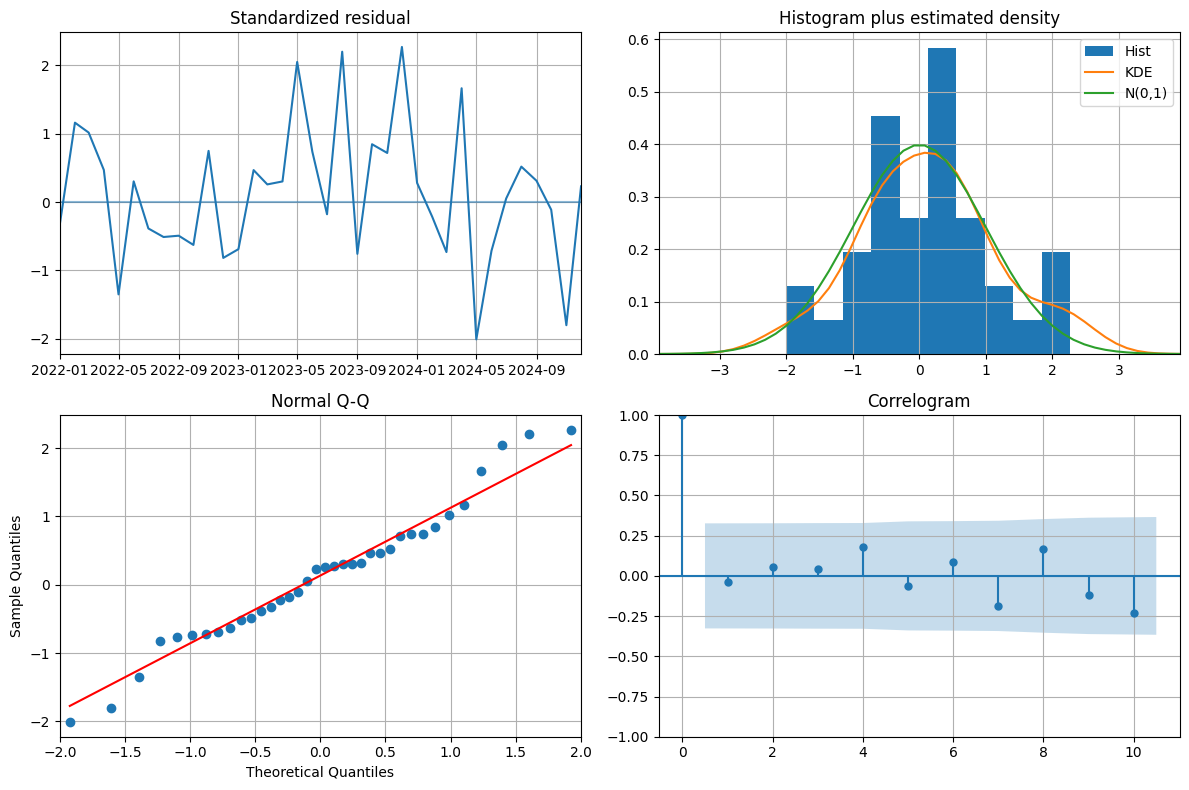

In [31]:
# %%
# Residual diagnostics – check if errors look like white noise
fig = sarima_model.plot_diagnostics(figsize=(12, 8))
plt.tight_layout()
plt.show()


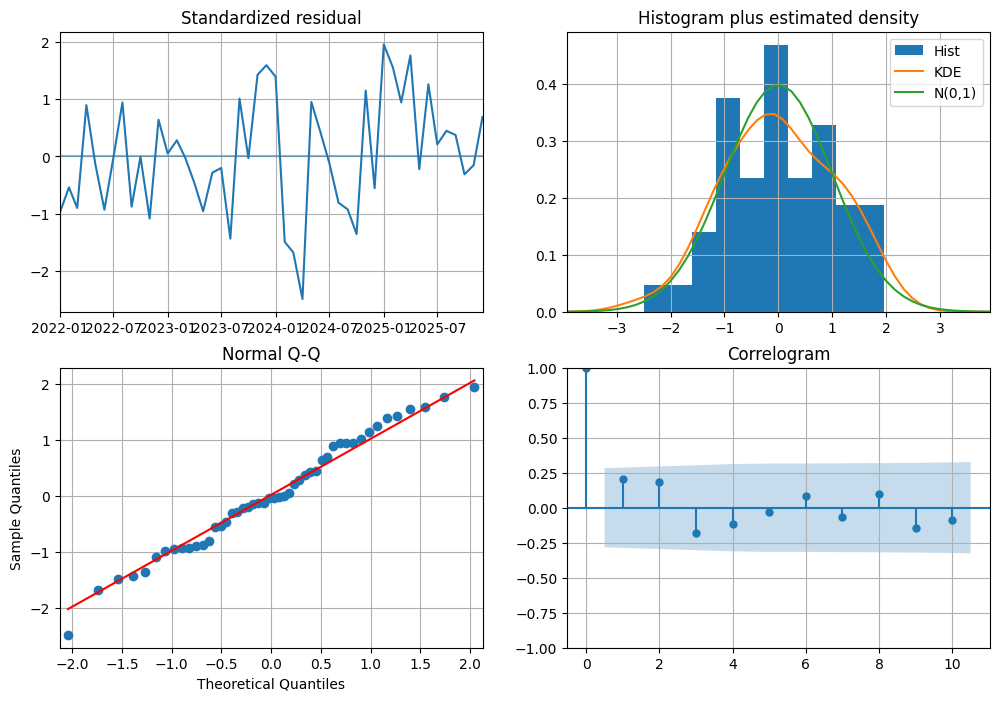

In [39]:
fig = rain_model.plot_diagnostics(figsize=(12,8))
plt.show()


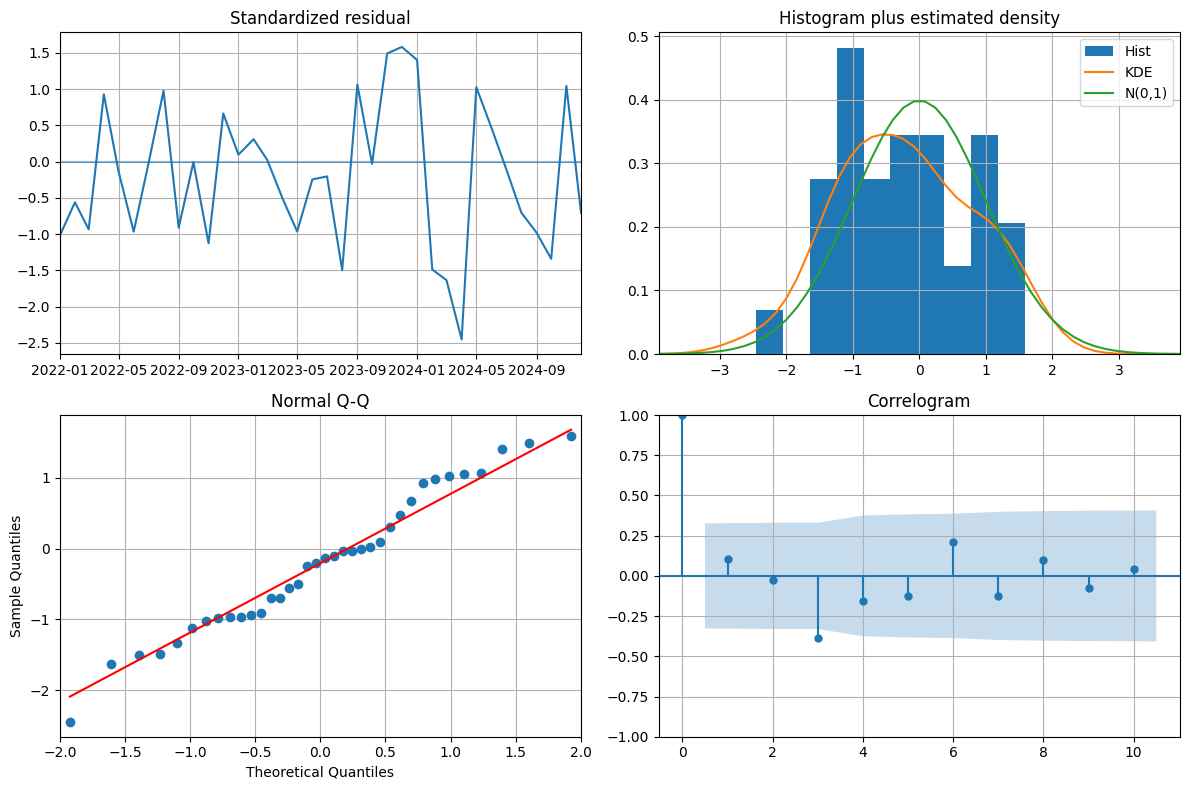

In [33]:
fig = rain_model.plot_diagnostics(figsize=(12, 8))
plt.tight_layout()
plt.show()



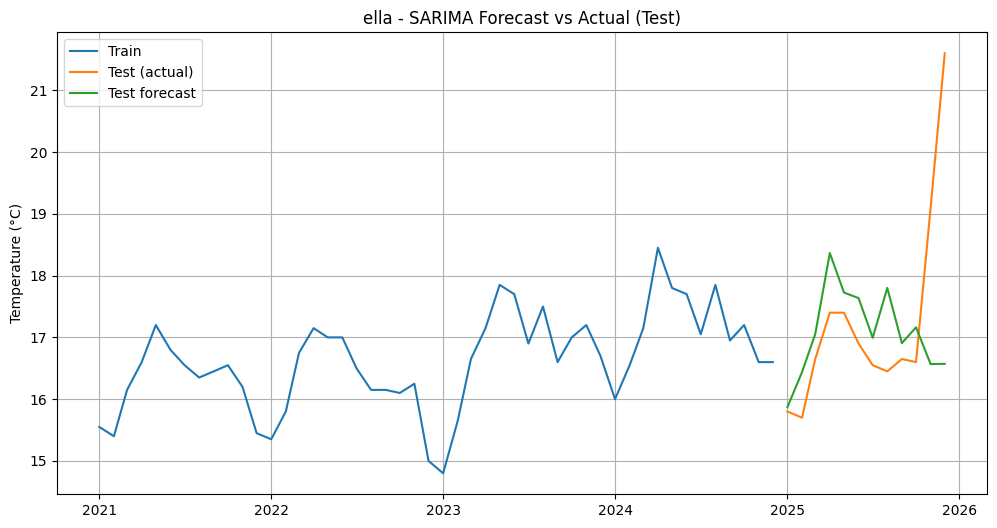

RMSE: 1.741
MAE : 1.118
MAPE: 5.98%


In [34]:
# %%
# Forecast on the hold-out test set
n_test = len(test)
test_fc = sarima_model.predict(n_periods=n_test)
test_index = test.index
fc_series = pd.Series(test_fc, index=test_index, name='forecast')

# Plot
plt.plot(train.index, train, label='Train')
plt.plot(test.index, test, label='Test (actual)')
plt.plot(fc_series.index, fc_series, label='Test forecast')
plt.legend()
plt.title(f'{location_id} - SARIMA Forecast vs Actual (Test)')
plt.ylabel('Temperature (°C)')
plt.show()

# Metrics
rmse = np.sqrt(mean_squared_error(test, fc_series))
mae = mean_absolute_error(test, fc_series)
mape = (
    np.abs((test - fc_series) / test)
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
).mean() * 100

print(f'RMSE: {rmse:.3f}')
print(f'MAE : {mae:.3f}')
print(f'MAPE: {mape:.2f}%')


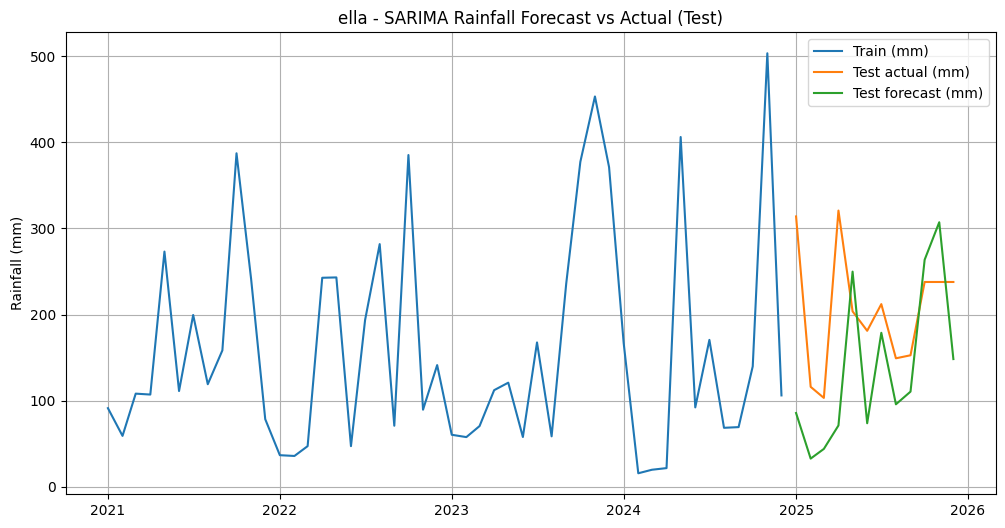

Rainfall RMSE: 114.626 mm
Rainfall MAE : 90.609 mm
Rainfall MAPE: 43.17%
Rainfall RMSE (log1p scale): 0.795


In [35]:
# --- Test forecast (log scale) ---
n_test = len(test_rain)
test_rain_fc_log = rain_model.predict(n_periods=n_test)
test_rain_index = test_rain.index

fc_rain_log = pd.Series(test_rain_fc_log, index=test_rain_index, name="forecast_log")

# back-transform for mm
test_rain_mm_true = np.expm1(test_rain)          # original scale
fc_rain_mm        = np.expm1(fc_rain_log)

# Plot on mm scale
plt.plot(rain_mm_capped.index[:-n_test], rain_mm_capped.iloc[:-n_test], label="Train (mm)")
plt.plot(test_rain_mm_true.index, test_rain_mm_true, label="Test actual (mm)")
plt.plot(fc_rain_mm.index, fc_rain_mm, label="Test forecast (mm)")
plt.legend()
plt.title(f"{location_id} - SARIMA Rainfall Forecast vs Actual (Test)")
plt.ylabel("Rainfall (mm)")
plt.show()

# Metrics on mm scale (dominated by big events)
rmse_rain = np.sqrt(mean_squared_error(test_rain_mm_true, fc_rain_mm))
mae_rain  = mean_absolute_error(test_rain_mm_true, fc_rain_mm)
mape_rain = (
    np.abs((test_rain_mm_true - fc_rain_mm) / test_rain_mm_true)
    .replace([np.inf, -np.inf], np.nan)
    .dropna()
).mean() * 100

print(f"Rainfall RMSE: {rmse_rain:.3f} mm")
print(f"Rainfall MAE : {mae_rain:.3f} mm")
print(f"Rainfall MAPE: {mape_rain:.2f}%")

# Optional: also report log-scale RMSE for the thesis
rmse_log = np.sqrt(mean_squared_error(test_rain, fc_rain_log))
print(f"Rainfall RMSE (log1p scale): {rmse_log:.3f}")


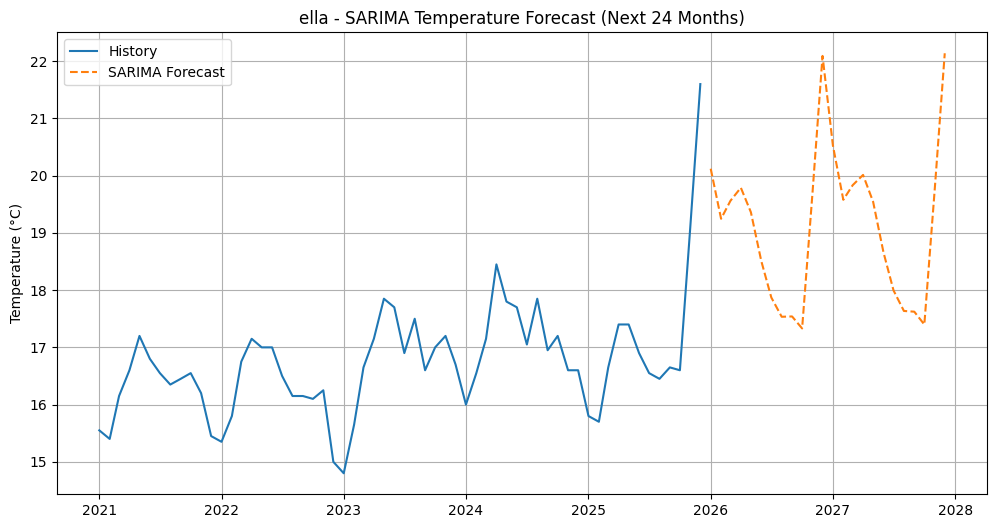

Saved single-location SARIMA forecast to: /Users/dev/Desktop/graphCeylon-API/models/recommender_service/sarima_forecast_single_location.csv


In [36]:
# %%
# Refit the selected SARIMA model on the FULL series
sarima_model_full = sarima_model.fit(ts)

# Forecast N future months
n_future = 24  # forecast horizon in months
future_fc = sarima_model_full.predict(n_periods=n_future)

future_index = pd.date_range(
    ts.index[-1] + pd.offsets.MonthBegin(1),
    periods=n_future,
    freq='MS'
)
future_series = pd.Series(future_fc, index=future_index, name='sarima_forecast')

# Plot history + forecast
plt.plot(ts.index, ts, label='History')
plt.plot(future_series.index, future_series, label='SARIMA Forecast', linestyle='--')
plt.legend()
plt.title(f'{location_id} - SARIMA Temperature Forecast (Next {n_future} Months)')
plt.ylabel('Temperature (°C)')
plt.show()

# Save to CSV
result_df = pd.DataFrame({
    'ds': future_series.index,
    'location_id': location_id,
    'pred_temp_sarima': future_series.values.round(2),
})

out_path = Path('sarima_forecast_single_location.csv')
result_df.to_csv(out_path, index=False)
print('Saved single-location SARIMA forecast to:', out_path.resolve())


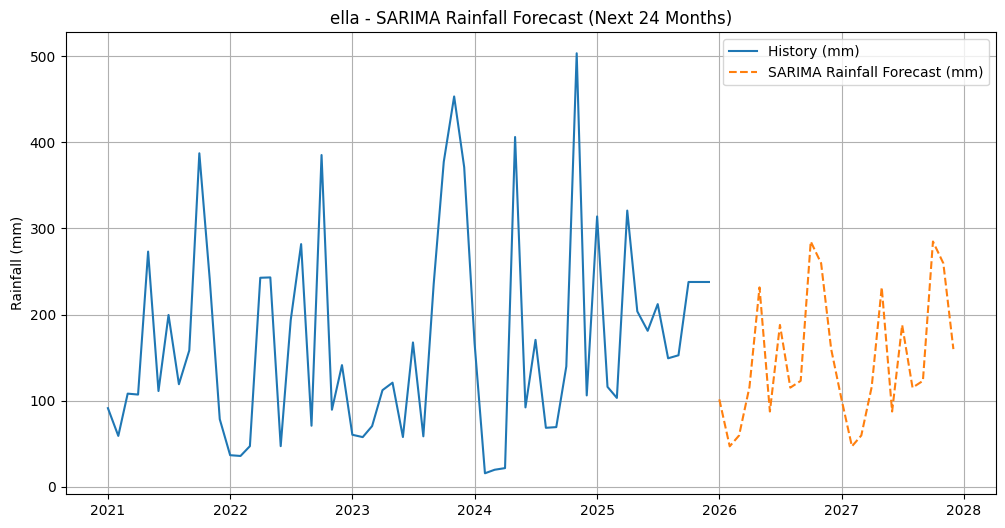

Saved single-location rainfall SARIMA forecast to: /Users/dev/Desktop/graphCeylon-API/models/recommender_service/sarima_rain_forecast_single_location.csv


In [38]:
# Refit rainfall SARIMA on full log series
# (use the trained auto_arima model `rain_model`)
rain_sarima_full = rain_model.fit(ts_log_rain)

n_rain_future = 24
rain_future_fc_log = rain_sarima_full.predict(n_periods=n_rain_future)

rain_future_index = pd.date_range(
    ts_log_rain.index[-1] + pd.offsets.MonthBegin(1),
    periods=n_rain_future,
    freq="MS",
)

# Back-transform from log1p to mm
rain_future_fc_mm = np.expm1(rain_future_fc_log)

rain_future_series_mm = pd.Series(
    rain_future_fc_mm,
    index=rain_future_index,
    name="rain_sarima_forecast_mm",
)

# Plot history + future rainfall
plt.plot(ts_rain_mm.index, ts_rain_mm.values, label="History (mm)")
plt.plot(
    rain_future_series_mm.index,
    rain_future_series_mm.values,
    label="SARIMA Rainfall Forecast (mm)",
    linestyle="--",
)
plt.legend()
plt.title(f"{rain_location_id} - SARIMA Rainfall Forecast (Next {n_rain_future} Months)")
plt.ylabel("Rainfall (mm)")
plt.show()

# Save to CSV
rain_result_df = pd.DataFrame(
    {
        "ds": rain_future_series_mm.index,
        "location_id": rain_location_id,
        "pred_rain_sarima_mm": rain_future_series_mm.values.round(1),
    }
)

rain_out_path = Path("sarima_rain_forecast_single_location.csv")
rain_result_df.to_csv(rain_out_path, index=False)
print("Saved single-location rainfall SARIMA forecast to:", rain_out_path.resolve())


In [40]:
from sklearn.metrics import mean_squared_error, mean_absolute_error
import numpy as np

temp_rmse = np.sqrt(mean_squared_error(test_temp, preds_temp))
temp_mae = mean_absolute_error(test_temp, preds_temp)

print("Temperature RMSE:", temp_rmse)
print("Temperature MAE:", temp_mae)


NameError: name 'test_temp' is not defined